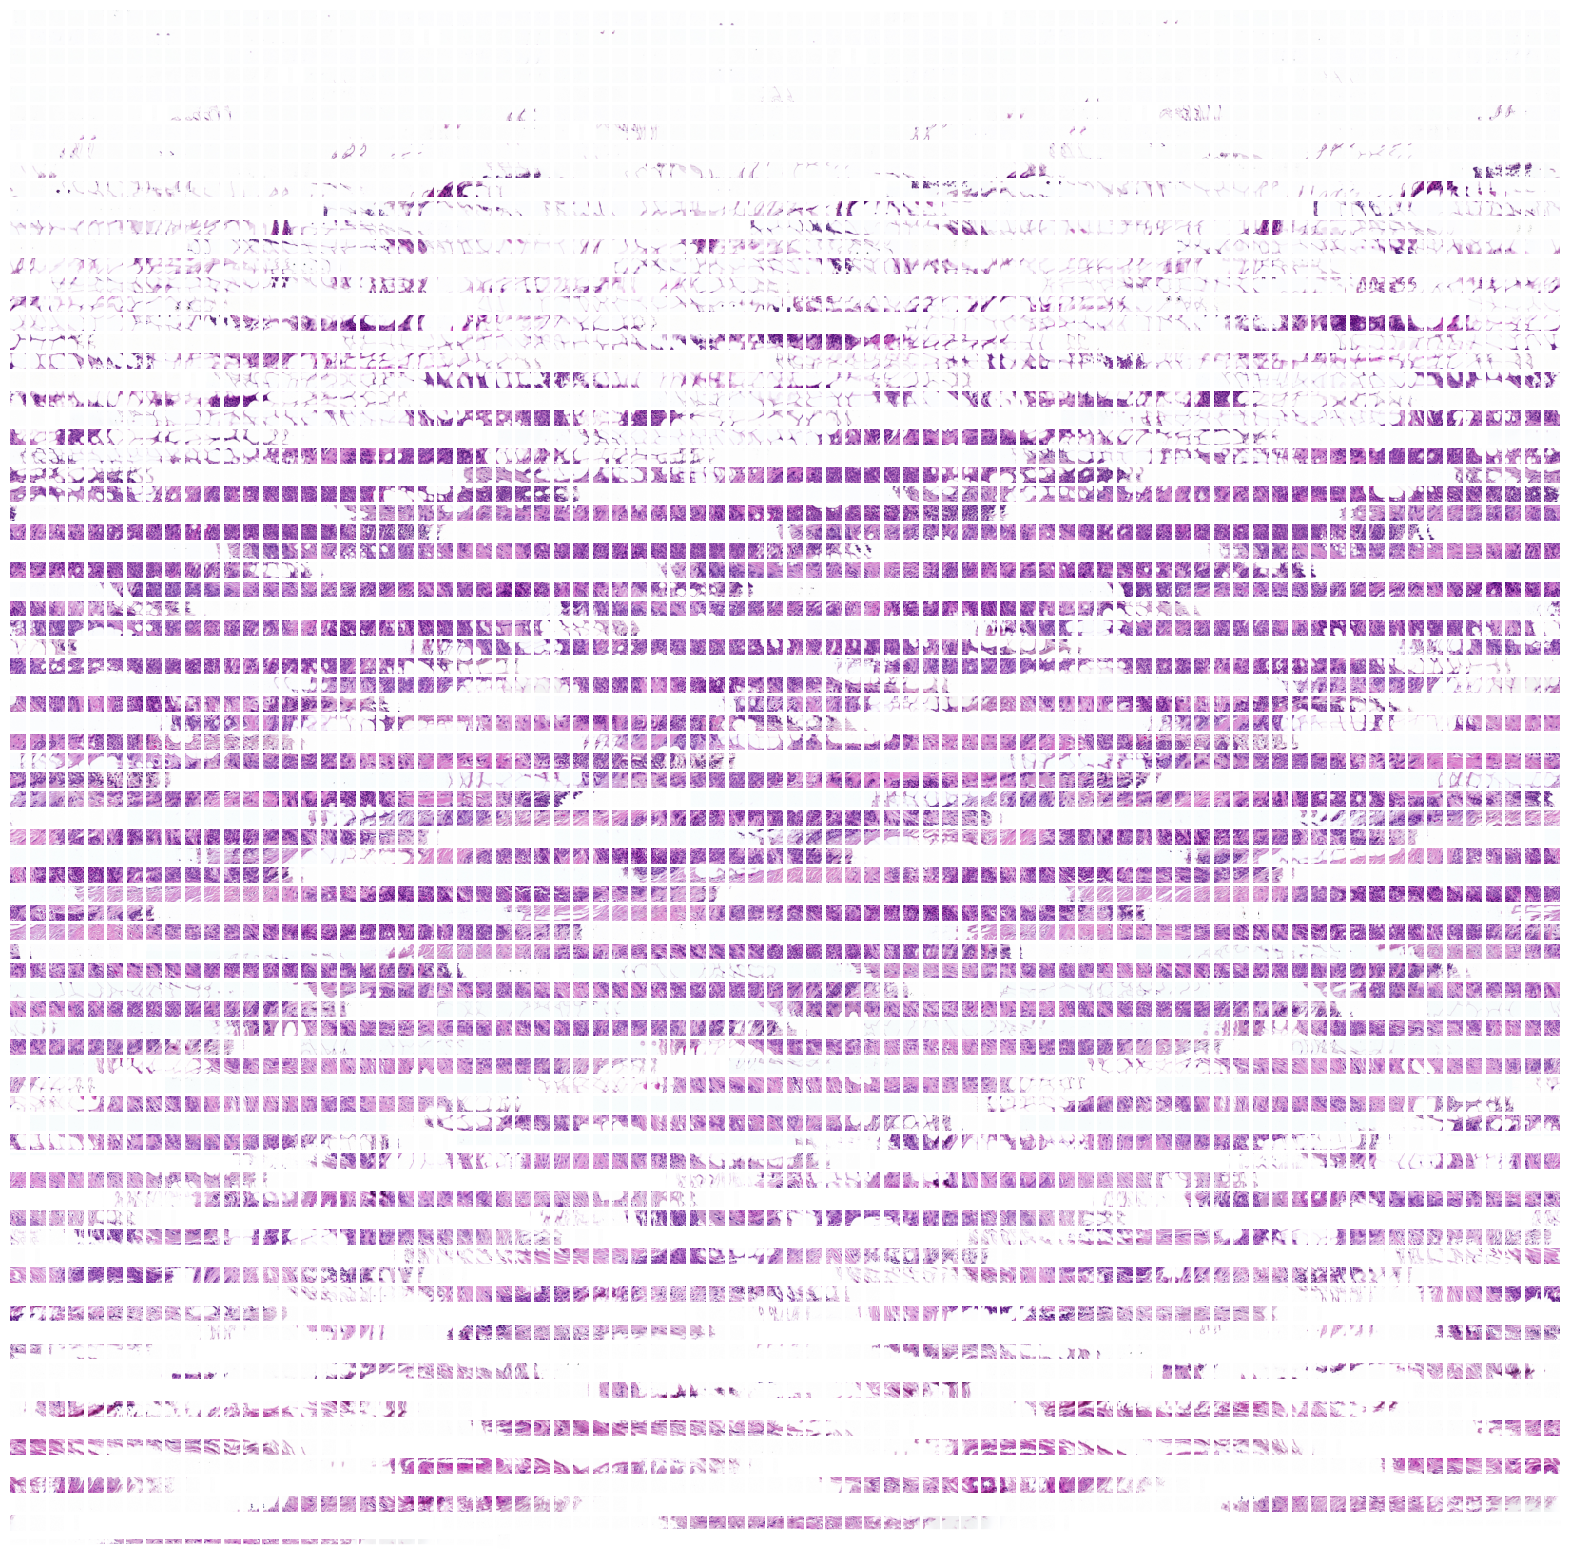

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

    
    
def extract_tiles(image_path, tile_size, overlap):
        image = cv2.imread(image_path)
    
    # Höhe und Breite des Bildes
        height, width, _ = image.shape
    
    #Schrit1tgröße basierend auf Überlappung
        step_x = tile_size - overlap
        step_y = tile_size - overlap
    
    #leeere liste für kacheln
        tiles = []
    
        for y in range(0, height, step_y):
            for x in range(0, width, step_x):
            # Schneide eine Kachel aus dem Bild
                tile = image[y:y+tile_size, x:x+tile_size]
                  
                # Kachel in Liste
                tiles.append(tile)
    
        return tiles

# Pfade zum Bild und anderen Dateien
image_path = "WSI.jpg"
tile_size = 224
overlap = 100 


plt.figure(figsize=(20, 20))


tiles = extract_tiles(image_path, tile_size, overlap)

if len(tiles) > 0: #spalten reihen 
    num_tiles = len(tiles)
    num_rows = int(np.ceil(np.sqrt(num_tiles)))
    num_cols = int(np.ceil(num_tiles / num_rows))

    #Kacheln anzeigen
    for i, tile in enumerate(tiles):
        plt.subplot(num_rows, num_cols, i+1)
        plt.imshow(cv2.cvtColor(tile, cv2.COLOR_BGR2RGB))
        plt.axis('off')
    
  
plt.show()


Größe der Liste tiles: 6426
Größe der Liste tiles (segmentations_masks): 6426


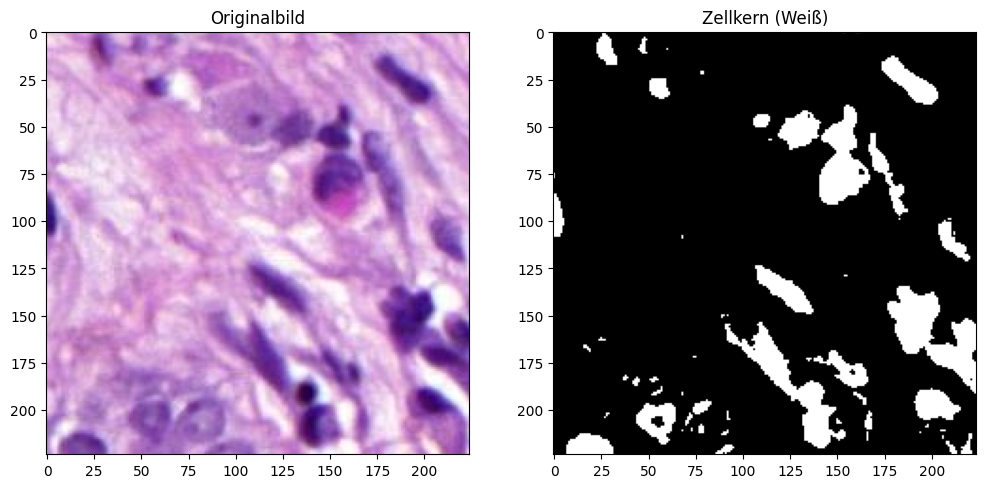

In [25]:
def segment_zellkern(tile):
 
    #Bild in den HSV-Modus
    hsv_tile = cv2.cvtColor(tile, cv2.COLOR_BGR2HSV)

    #Farbbereich für dunklere Zellkerne im HSV-Modus
    lower_bound = np.array([0, 0, 0], dtype=np.uint8)
    upper_bound = np.array([255, 255, 175], dtype=np.uint8)

    #Maske für  Zellkerne
    zellkernMask = cv2.inRange(hsv_tile, lower_bound, upper_bound)


    #inverted_mask = cv2.bitwise_not(mask)
    return zellkernMask
    


tiles = extract_tiles(image_path, tile_size, overlap)

segmentation_masks = [segment_zellkern(tile) for tile in tiles]

#Index des gewünschten Tiles
sample_tile_index = 4566 # kann sein dass bei manchen nur weiß rauskommt s. oben
print("Größe der Liste tiles:", len(tiles))
print("Größe der Liste tiles (segmentations_masks):", len(segmentation_masks))

plt.figure(figsize=(12, 6))

# Originalbild
plt.subplot(1, 2, 1)
plt.title('Originalbild')
plt.imshow(cv2.cvtColor(tiles[sample_tile_index], cv2.COLOR_BGR2RGB))

# Zellkern-Maske
plt.subplot(1, 2, 2)
plt.title('Zellkern (Weiß)')
plt.imshow(segmentation_masks[sample_tile_index], cmap="gray")

plt.show()

/var/folders/tg/7hkq19l528d1017002_dnvjr0000gn/T/ipykernel_17759/4135678896.py:3: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


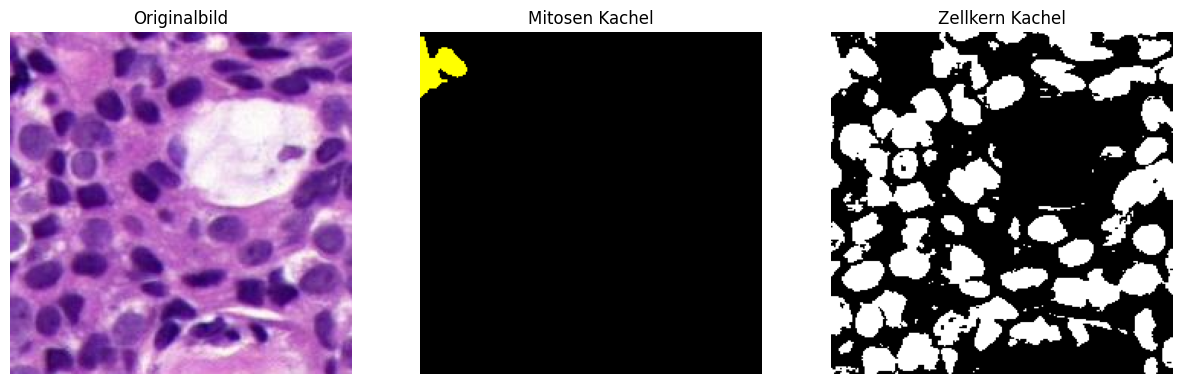

In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

class MitosisSegmentation:
    def __init__(self, image_path, annotations_path, offset_path, tile_size=224, overlap=100):
        self.image_path = image_path
        self.annotations_path = annotations_path
        self.offset_path = offset_path
        self.tile_size = tile_size 
        self.overlap = overlap
        self.image = cv2.imread(image_path)
        self.mitose_coords = self.load_annotations()
        self.offset = self.load_offset()

    def load_offset(self): #offset daten waus csv datei rauslesen 
        offset = pd.read_csv(self.offset_path, delimiter=';') #https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
        offset_x, offset_y = offset['x'].values[0], offset['y'].values[0]
        return {'x': offset_x, 'y': offset_y}

    def load_annotations(self): #coords von mitosen aus csv datei
        annotations = pd.read_csv(self.annotations_path, delimiter=';')
        mitose_coords = []
        for index, row in annotations.iterrows(): #Quelle: https://remarkablemark.org/blog/2020/08/26/python-iterate-csv-rows/
            coords_list = eval(row['coords'])
            for coords in coords_list: 
                mitose_coords.append(coords)
        return mitose_coords #als mitose_coords abgespeichert

    def extract_tiles(self): #zum extrahieren des bildes (basierend auf überlappung und größe)
        tiles = [] #liste für kacheln 
        tile_coords = [] # liste für die coords der kacheln
        height, width, _ = self.image.shape
        #schitte in x und y richtungen
        step_x = self.tile_size - self.overlap 
        step_y = self.tile_size - self.overlap
        
        #iteration um kacheln zu extrahieren
        for y in range(0, height - self.tile_size + 1, step_y):
            for x in range(0, width - self.tile_size + 1, step_x):
                tile = self.image[y:y + self.tile_size, x:x + self.tile_size]
                tiles.append(tile)
                tile_coords.append((x, y))

        return tiles, tile_coords

    def segment_zellkern(self, tile):
        hsv_tile = cv2.cvtColor(tile, cv2.COLOR_BGR2HSV)
        lower_bound = np.array([0, 0, 0], dtype=np.uint8)
        upper_bound = np.array([255, 255, 175], dtype=np.uint8)
        zellkernMask = cv2.inRange(hsv_tile, lower_bound, upper_bound)
        return zellkernMask

    def segment_mitose(self, tile, tile_coord):
        #maske für zellkerne in kachel
        zellkern_mask = self.segment_zellkern(tile)
        
        #um konturen der zellkerne zu finden -> mit zellkernMask
        contours, _ = cv2.findContours(zellkern_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        
        #maske erstellen um dann zellkern als mitose zu kennzeicnen
        mask_with_mitosis = np.zeros(tile.shape, dtype=np.uint8)
    
        mitose_detected = False
        for mitose_coord in self.mitose_coords:
            global_x, global_y = mitose_coord
            local_x = int(global_x - self.offset['x'] - tile_coord[0])
            local_y = int(global_y - self.offset['y'] - tile_coord[1])
    
            # checken der Kontur, ob die mitose in kachel liegt
            for contour in contours:
                dist = cv2.pointPolygonTest(contour, (local_x, local_y), False) #Quelle: https://stackoverflow.com/questions/57312028/problem-with-using-cv2-pointpolygontest-and-cv2-polylines
                if dist >= 0:  #wenn drin
                    cv2.drawContours(mask_with_mitosis, [contour], 0, (0, 255, 255), -1)  # Gelb einfärben; Quelle: https://stackoverflow.com/questions/48948769/how-to-draw-contours-using-opencv-in-python
                    mitose_detected = True
                    break  
                    
        return mask_with_mitosis, mitose_detected



    def visualize_results(self, index):
        tiles, tile_coords = self.extract_tiles()
        plt.figure(figsize=(15, 5))  

        mitoses_tiles = [] #nur tiles mit mitosen werden angezeigt -> durch coords in annotations
        mitoses_masks = [] #liste mit masken mitosen
        zellkern_masks = [] #masken der zellkerne

        #durch alle kacheln gehen, um mitosen zu erkennen + maske erstellen
        for tile, tile_coord in zip(tiles, tile_coords):
            combined_mask, mitose_detected = self.segment_mitose(tile, tile_coord)
            zellkern_mask = self.segment_zellkern(tile)  # Segmentierung der Zellkerne
            if mitose_detected: #wenn mitose gibt
                mitoses_tiles.append(tile) #kachel in liste hinzufügen 
                mitoses_masks.append(combined_mask) #mitose maske auch
                zellkern_masks.append(zellkern_mask)  # Zellkernmaske für die gleiche Kachel speichern

               
    
        if len(mitoses_tiles) > 0:
            
            plt.subplot(1, 3, 1)
            plt.imshow(cv2.cvtColor(mitoses_tiles[index], cv2.COLOR_BGR2RGB))
            plt.title("Originalbild")
            plt.axis('off')

            plt.subplot(1, 3, 2)
            plt.imshow(cv2.cvtColor(mitoses_masks[index], cv2.COLOR_BGR2RGB))
            plt.title("Mitosen Kachel")
            plt.axis('off')

            plt.subplot(1, 3, 3)
            plt.imshow(zellkern_masks[index], cmap='gray')
            plt.title("Zellkern Kachel")
            plt.axis('off')

            plt.show()
      


image_path = "WSI.jpg"
annotations_path = 'annotations.csv'
offset_path = 'offset.csv'

detector = MitosisSegmentation(image_path, annotations_path, offset_path)
detector.visualize_results(34) 
